# Segmentation with U-Net

In [1]:
# Importing necessary libraries
import os
import numpy as np
from tqdm import tqdm
from skimage.io import imread, imshow
from skimage.transform import resize
from PIL import Image
import matplotlib.pyplot as plt
from tensorflow.keras.layers import (Input, Lambda, Conv2D, Dropout, MaxPooling2D, 
                                    Conv2DTranspose, concatenate)

from tensorflow.keras import Model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard

In [2]:
TRAIN_PATH = '../input/nucleiimagesmasksfromdsb2018/data-science-bowl-2018/stage1_train/'
TRAINMASKS_PATH = '../input/nucleiimagesmasksfromdsb2018/data-science-bowl-2018/stage1_train_combinedmasks/'
TEST_PATH = '../input/nucleiimagesmasksfromdsb2018/data-science-bowl-2018/stage1_test/'

In [3]:
# Params
IMG_WIDTH = 128
IMG_HEIGHT = 128
IMG_CHANNELS = 3

# Data Preprocessing

In [4]:
train_ids = next(os.walk(TRAIN_PATH))[1]
test_ids = next(os.walk(TEST_PATH))[1]
print(len(train_ids), len(test_ids))

670 65


In [5]:
X_train = np.zeros((len(train_ids), IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), dtype=np.uint8)
y_train = np.zeros((len(train_ids), IMG_HEIGHT, IMG_WIDTH, 1), dtype=np.bool)

In [6]:
# Train images
print('Resizing training images and masks')
for n, id_ in tqdm(enumerate(train_ids), total=len(train_ids)):
    path = TRAIN_PATH + id_
    img = imread(path+'/images/'+id_+'.png')[:,:,:IMG_CHANNELS]
    img = resize(img, (IMG_HEIGHT, IMG_WIDTH), mode='constant', preserve_range=True)
    X_train[n] = img
    '''
    # This code is only needed to combine masks of diff cells into one mask
    # Adding diff masks for diff cells into one mask
    mask = np.zeros((IMG_HEIGHT, IMG_WIDTH, 1), dtype=np.bool)
    for mask_file in next(os.walk(path+'/masks/'))[2]:
        mask_ = imread(path+'/masks/'+mask_file)
        mask_ = np.expand_dims(resize(
                mask_, (IMG_HEIGHT, IMG_WIDTH), mode='constant', preserve_range=True),
                              axis=-1)
        mask = np.maximum(mask, mask_)
        
    y_train[n] = mask'''
    mask = imread(TRAINMASKS_PATH+id_+'.png')
    mask = np.expand_dims(resize(
                mask, (IMG_HEIGHT, IMG_WIDTH), mode='constant', preserve_range=True),
                              axis=-1)
    y_train[n] = mask

  0%|          | 0/670 [00:00<?, ?it/s]

Resizing training images and masks


100%|██████████| 670/670 [04:24<00:00,  2.53it/s]


In [7]:
'''
# Code to Save the masks and zip it for downloading
'''
os.makedirs('../outputs/train_masks')
def img_frombytes(data):
    size = (data.shape[0],data.shape[1])
    databytes = np.packbits(data, axis=1)
    return Image.frombytes(mode='1', size=size, data=databytes)

for n, id_ in tqdm(enumerate(train_ids), total=len(train_ids)):
    print(train_ids[n],end=' ')
    im = img_frombytes((y_train[n]*255).astype(np.uint8))
    im.save('../outputs/train_masks/'+train_ids[n]+'.png')
    print(' Saved to '+'../outputs/train_masks/'+train_ids[n]+'.png\n')
    
import shutil
OUTPUT_NAME = 'download_folder'
DIRECTORY_TO_ZIP = '../outputs/train_masks/'
shutil.make_archive(OUTPUT_NAME, 'zip', DIRECTORY_TO_ZIP)

 37%|███▋      | 246/670 [00:00<00:00, 1230.54it/s]

00071198d059ba7f5914a526d124d28e6d010c92466da21d4a04cd5413362552  Saved to ../outputs/train_masks/00071198d059ba7f5914a526d124d28e6d010c92466da21d4a04cd5413362552.png

003cee89357d9fe13516167fd67b609a164651b21934585648c740d2c3d86dc1  Saved to ../outputs/train_masks/003cee89357d9fe13516167fd67b609a164651b21934585648c740d2c3d86dc1.png

00ae65c1c6631ae6f2be1a449902976e6eb8483bf6b0740d00530220832c6d3e  Saved to ../outputs/train_masks/00ae65c1c6631ae6f2be1a449902976e6eb8483bf6b0740d00530220832c6d3e.png

0121d6759c5adb290c8e828fc882f37dfaf3663ec885c663859948c154a443ed  Saved to ../outputs/train_masks/0121d6759c5adb290c8e828fc882f37dfaf3663ec885c663859948c154a443ed.png

01d44a26f6680c42ba94c9bc6339228579a95d0e2695b149b7cc0c9592b21baf  Saved to ../outputs/train_masks/01d44a26f6680c42ba94c9bc6339228579a95d0e2695b149b7cc0c9592b21baf.png

0280fa8f60f6bcae0f97d93c28f60be194f9309ff610dc5845e60455b0f87c21  Saved to ../outputs/train_masks/0280fa8f60f6bcae0f97d93c28f60be194f9309ff610dc5845e60455b0f87c

 55%|█████▌    | 370/670 [00:00<00:00, 1093.34it/s]

5afcbfd0dd64392aa1e233b996d0bfb4354ee7119f30ae111c33d0fe4df11590  Saved to ../outputs/train_masks/5afcbfd0dd64392aa1e233b996d0bfb4354ee7119f30ae111c33d0fe4df11590.png

5b0bde771bc67c505d1b59405cbcad0a2766ec3ee4e35852e959552c1b454233  Saved to ../outputs/train_masks/5b0bde771bc67c505d1b59405cbcad0a2766ec3ee4e35852e959552c1b454233.png

5b12df18e4ae4df5af06052584cf0e6bef58ee2a220653890636eef88a944e14  Saved to ../outputs/train_masks/5b12df18e4ae4df5af06052584cf0e6bef58ee2a220653890636eef88a944e14.png

5b2ccfb94dedf2ec8797c0404fc324888e35ab903c41bb26f070552033ca8e6c  Saved to ../outputs/train_masks/5b2ccfb94dedf2ec8797c0404fc324888e35ab903c41bb26f070552033ca8e6c.png

5ba4facefc949c920d7054813a3e846b000969da2ed860148bdfd18456f59bcc  Saved to ../outputs/train_masks/5ba4facefc949c920d7054813a3e846b000969da2ed860148bdfd18456f59bcc.png

5bb8508ff8ec8683fc6a8aa6bd470f6feb3af4eccdca07f51a1ebc9dad67cfb8  Saved to ../outputs/train_masks/5bb8508ff8ec8683fc6a8aa6bd470f6feb3af4eccdca07f51a1ebc9dad67cf

 88%|████████▊ | 590/670 [00:00<00:00, 1061.19it/s]

 Saved to ../outputs/train_masks/a6001531274f9ad16e0ced40380f9667b9149558dea7053f7a7db18f5cd028c0.png

a6515d73077866808ad4cb837ecdac33612527b8a1041e82135e40fce2bb9380  Saved to ../outputs/train_masks/a6515d73077866808ad4cb837ecdac33612527b8a1041e82135e40fce2bb9380.png

a6593632dcbbe4c9e9429a9cec573d26fd8c91a47d554d315f25e7c2e0280ee3  Saved to ../outputs/train_masks/a6593632dcbbe4c9e9429a9cec573d26fd8c91a47d554d315f25e7c2e0280ee3.png

a65bbfc5673e8053b6ce49f39c79cf3a846fe5cc46dd93105f74fb07cf44606d  Saved to ../outputs/train_masks/a65bbfc5673e8053b6ce49f39c79cf3a846fe5cc46dd93105f74fb07cf44606d.png

a6e81120d1cb9f71f8a25f90a5d56c4b714a642fc496a705e38921fd90a3f69c  Saved to ../outputs/train_masks/a6e81120d1cb9f71f8a25f90a5d56c4b714a642fc496a705e38921fd90a3f69c.png

a7a581e6760df4701941670e73d72533e3b0fbd7563488ad92772b41f7709710  Saved to ../outputs/train_masks/a7a581e6760df4701941670e73d72533e3b0fbd7563488ad92772b41f7709710.png

a7f6194ddbeaefb1da571226a97785d09ccafc5893ce3c77078d2040b

100%|██████████| 670/670 [00:00<00:00, 1069.33it/s]


f93ec5e683d81005ffc2a84a1c0299b2406ad14b764b824e013f7ca3a13833b5  Saved to ../outputs/train_masks/f93ec5e683d81005ffc2a84a1c0299b2406ad14b764b824e013f7ca3a13833b5.png

f952cc65376009cfad8249e53b9b2c0daaa3553e897096337d143c625c2df886  Saved to ../outputs/train_masks/f952cc65376009cfad8249e53b9b2c0daaa3553e897096337d143c625c2df886.png

f9ac03b0344ce8c48bc058448541f9211a1e5f4c94fdaf633dd534328d8610ab  Saved to ../outputs/train_masks/f9ac03b0344ce8c48bc058448541f9211a1e5f4c94fdaf633dd534328d8610ab.png

f9ea1a1159c33f39bbe5f18bb278d961188b40508277eab7c0b4b91219b37b5d  Saved to ../outputs/train_masks/f9ea1a1159c33f39bbe5f18bb278d961188b40508277eab7c0b4b91219b37b5d.png

fa73f24532b3667718ede7ac5c2e24ad7d3cae17b0a42ed17bbb81b15c28f4ae  Saved to ../outputs/train_masks/fa73f24532b3667718ede7ac5c2e24ad7d3cae17b0a42ed17bbb81b15c28f4ae.png

fa751ff3a6332c95cb5cb1d28563553914295e9e7d35c4b6bd267241e8a0787c  Saved to ../outputs/train_masks/fa751ff3a6332c95cb5cb1d28563553914295e9e7d35c4b6bd267241e8a078

'/kaggle/working/download_folder.zip'

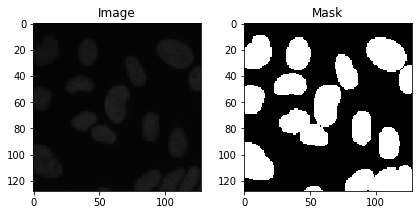

In [8]:
i = 10
plt.subplot(121)
imshow(X_train[i])
plt.title('Image')
plt.subplot(122)
imshow(np.squeeze(y_train[i]))
plt.title('Mask')
plt.show()

In [10]:
X_test = np.zeros((len(test_ids), IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), dtype=np.uint8)
sizes_test = []

In [11]:
# Test images
print('Resizing test images and masks')
for n, id_ in tqdm(enumerate(test_ids), total=len(test_ids)):
    path = TEST_PATH + id_
    img = imread(path+'/images/'+id_+'.png')[:,:,:IMG_CHANNELS]
    img = resize(img, (IMG_HEIGHT, IMG_WIDTH), mode='constant', preserve_range=True)
    X_test[n] = img

  0%|          | 0/65 [00:00<?, ?it/s]

Resizing test images and masks


100%|██████████| 65/65 [00:21<00:00,  2.99it/s]


# Building the U-Net Model

In [12]:
# Inputs
inputs = Input((IMG_WIDTH, IMG_HEIGHT, IMG_CHANNELS))
# Change integer to float and also scale pixel values
s = Lambda(lambda x: x/255.0)(inputs)

# Contraction/Encoder path
# Block 1
c1 = Conv2D(filters=16, kernel_size=(3,3),
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(s)
c1 = Dropout(0.1)(c1)
c1 = Conv2D(filters=16, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(c1)
p1 = MaxPooling2D(pool_size=(2,2))(c1)
# Block 2
c2 = Conv2D(filters=32, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(p1)
c2 = Dropout(0.1)(c2)
c2 = Conv2D(filters=32, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(c2)
p2 = MaxPooling2D(pool_size=(2,2))(c2)
# Block 3
c3 = Conv2D(filters=64, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(p2)
c3 = Dropout(0.2)(c3)
c3 = Conv2D(filters=64, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(c3)
p3 = MaxPooling2D(pool_size=(2,2))(c3)
# Block 4
c4 = Conv2D(filters=128, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(p3)
c4 = Dropout(0.2)(c4)
c4 = Conv2D(filters=128, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(c4)
p4 = MaxPooling2D(pool_size=(2,2))(c4)
# Block 5
c5 = Conv2D(filters=256, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(p4)
c5 = Dropout(0.3)(c5)
c5 = Conv2D(filters=256, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(c5)

# Expansion/Decoder path
# Block 6
u6 = Conv2DTranspose(filters=128, kernel_size=(2,2), strides = (2,2), padding='same')(c5)
u6 = concatenate([u6, c4])
c6 = Conv2D(filters=128, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(u6)
c6 = Dropout(0.2)(c6)
c6 = Conv2D(filters=128, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(c6)

# Block 7
u7 = Conv2DTranspose(filters=64, kernel_size=(2,2), strides = (2,2), padding='same')(c6)
u7 = concatenate([u7, c3])
c7 = Conv2D(filters=64, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(u7)
c7 = Dropout(0.2)(c7)
c7 = Conv2D(filters=64, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(c7)

# Block 8
u8 = Conv2DTranspose(filters=32, kernel_size=(2,2), strides = (2,2), padding='same')(c7)
u8 = concatenate([u8, c2])
c8 = Conv2D(filters=32, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(u8)
c8 = Dropout(0.1)(c8)
c8 = Conv2D(filters=32, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(c8)

# Block 9
u9 = Conv2DTranspose(filters=16, kernel_size=(2,2), strides = (2,2), padding='same')(c8)
u9 = concatenate([u9, c1])
c9 = Conv2D(filters=16, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(u9)
c9 = Dropout(0.1)(c9)
c9 = Conv2D(filters=16, kernel_size=(3,3), 
                            activation='relu', kernel_initializer='he_normal',
                           padding='same')(c9)
# Outputs
outputs = Conv2D(filters=1, kernel_size=(1,1), 
                            activation='sigmoid')(c9)

model = Model(inputs=[inputs], outputs=[outputs])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 128, 128, 3) 0                                            
__________________________________________________________________________________________________
lambda (Lambda)                 (None, 128, 128, 3)  0           input_1[0][0]                    
__________________________________________________________________________________________________
conv2d (Conv2D)                 (None, 128, 128, 16) 448         lambda[0][0]                     
__________________________________________________________________________________________________
dropout (Dropout)               (None, 128, 128, 16) 0           conv2d[0][0]                     
______________________________________________________________________________________________

# Model Training

In [13]:
# Callbacks
callbacks_list = [ModelCheckpoint('nuclei_model.h5', verbose=1, save_best_only=True),
                  EarlyStopping(patience=2, monitor='val_loss'),
                  TensorBoard(log_dir='logs')]

In [14]:
model_results = model.fit(X_train, y_train, validation_split=0.1, batch_size=32, 
                          epochs=25, callbacks=callbacks_list)

Epoch 1/25
19/19 [==============================] - 10s 167ms/step - loss: 0.6614 - accuracy: 0.6771 - val_loss: 0.5278 - val_accuracy: 0.8044

Epoch 00001: val_loss improved from inf to 0.52778, saving model to nuclei_model.h5
Epoch 2/25
19/19 [==============================] - 1s 74ms/step - loss: 0.4645 - accuracy: 0.7811 - val_loss: 0.3475 - val_accuracy: 0.8144

Epoch 00002: val_loss improved from 0.52778 to 0.34746, saving model to nuclei_model.h5
Epoch 3/25
19/19 [==============================] - 1s 74ms/step - loss: 0.2958 - accuracy: 0.8310 - val_loss: 0.2347 - val_accuracy: 0.9197

Epoch 00003: val_loss improved from 0.34746 to 0.23468, saving model to nuclei_model.h5
Epoch 4/25
19/19 [==============================] - 1s 74ms/step - loss: 0.2005 - accuracy: 0.9271 - val_loss: 0.1803 - val_accuracy: 0.9345

Epoch 00004: val_loss improved from 0.23468 to 0.18028, saving model to nuclei_model.h5
Epoch 5/25
19/19 [==============================] - 1s 75ms/step - loss: 0.1825 - 

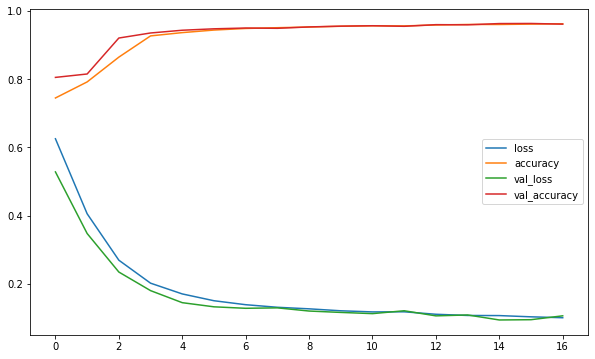

In [15]:
plt.figure(figsize=[10,6])
for key in model_results.history.keys():
    plt.plot(model_results.history[key], label=key)
    
plt.legend()
plt.show()

Further visualizations can be done using the `logs` in `output` folder. The `logs` was created using `TensorBoard`.

# Model Evaluation

In [16]:
preds_train = model.predict(X_train[:int(X_train.shape[0]*0.9)], verbose=1)
y_true_train = y_train[:int(y_train.shape[0]*0.9)]
preds_val = model.predict(X_train[int(X_train.shape[0]*0.9):], verbose=1)
y_true_val = y_train[int(y_train.shape[0]*0.9):]
preds_test = model.predict(X_test, verbose=1)

3/3 [==============================] - 0s 84ms/step


In [17]:
# Thresholding
preds_train_t = (preds_train > 0.5).astype(np.uint8)
preds_val_t = (preds_val > 0.5).astype(np.uint8)
preds_test_t = (preds_test > 0.5).astype(np.uint8)

In [18]:
# Show images
def show_images(i, ti, orgimg, y_true, preds, preds_t):
    plt.figure(figsize=(8,8))
    plt.subplot(221)
    imshow(orgimg[i])
    plt.title('Image to be Segmented')
    plt.subplot(222)
    imshow(y_true[ti])
    plt.title('Segmentation Ground Truth')
    plt.subplot(223)
    imshow(preds[ti])
    plt.title('Predicted Segmentation')
    plt.subplot(224)
    imshow(preds_t[ti])
    plt.title('Thresholded Segmentation')
    plt.show()

/opt/conda/lib/python3.7/site-packages/skimage/io/_plugins/matplotlib_plugin.py:150: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


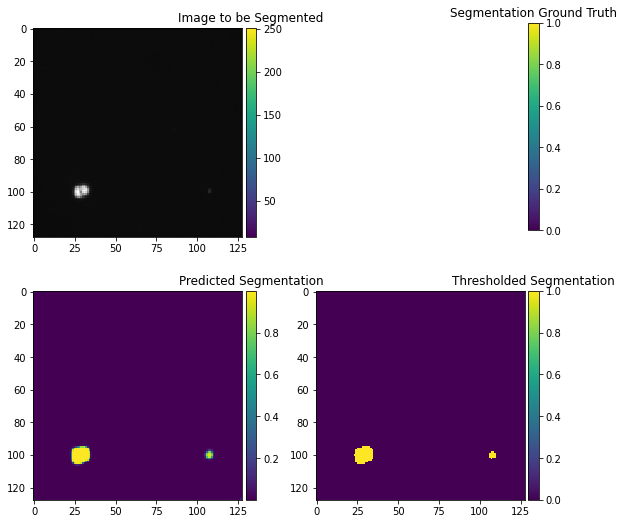

In [19]:
# On Train
# train max 602
i = 602
show_images(i, i, X_train, y_true_train, preds_train, preds_train_t)

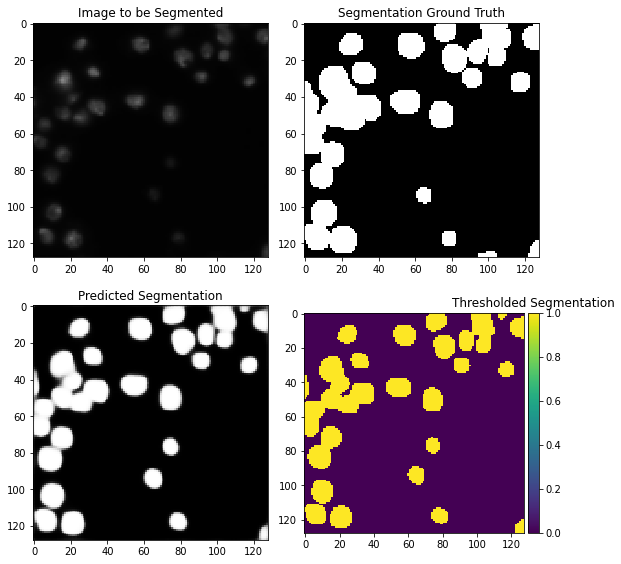

In [20]:
# On Val
# i = 603:669
i = 660
show_images(i, i-603,  X_train, y_true_val, preds_val, preds_val_t)

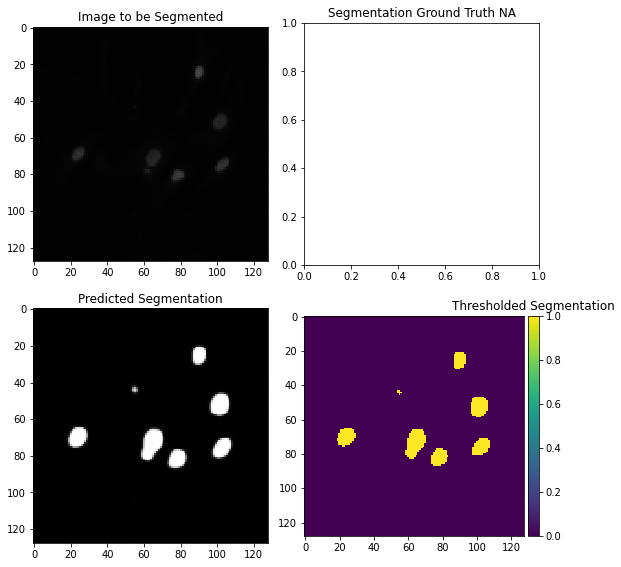

In [21]:
# On Test
# Ground Truths Not Available
i = 0
plt.figure(figsize=(8,8))
plt.subplot(221)
imshow(X_test[i])
plt.title('Image to be Segmented')
plt.subplot(222)
plt.title('Segmentation Ground Truth NA')
plt.subplot(223)
imshow(preds_test[i])
plt.title('Predicted Segmentation')
plt.subplot(224)
imshow(preds_test_t[i])
plt.title('Thresholded Segmentation')
plt.show()

In [22]:
print("Evaluate on val data")
results = model.evaluate(X_train[int(X_train.shape[0]*0.9):], y_train[int(y_train.shape[0]*0.9):], batch_size=128)
print("Test Loss:", results[0])
print("Test Acc :", results[1]*100, "%")

Evaluate on val data
1/1 [==============================] - 1s 614ms/step - loss: 0.1065 - accuracy: 0.9604
Test Loss: 0.10651921480894089
Test Acc : 96.03571891784668 %


It would have been much better to evaluate on new test set other than validation set but here the data is too small to split into train, validation and test sets. One can extend this work by using techniques of data augmentation which may be considered in the next version of this notebook.